<a href="https://colab.research.google.com/github/naserhusovic-droid/dsb_capston/blob/main/CAPSTONE_Naser_Husovic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# First I find the Data, check them and find wich libraries I need to import for my CAPSTONE PROJECT
# I do import below

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import product
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [132]:
# Here I read my first exel datasets, wich have 9 but I will fokus on 5 main sheets
# below I will explore each of them in depth
im1 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx')

In [133]:
for i, sheet in enumerate(xls1.sheet_names, start=1):
  globals()['im_%s'%str(i)] = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name=sheet)

In [134]:
xls1 = pd.ExcelFile('/content/DTM Europe_Q1_2026_Dataset.xlsx')
xls1.sheet_names

['About',
 'Summary',
 'First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence',
 'Sources',
 'ISO3']

In [15]:
# Here I do with first column 'First_Arrival_Countries_Monthly' from my first dataset
# 'im1' - is for first datasets, '_1' is for first column
im1_1 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'First_Arrival_Countries_Monthly')

In [16]:
im1_1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1128 entries, 0 to 1127
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1128 non-null   datetime64[ns]
 1   Year                       1128 non-null   int64         
 2   Month                      1128 non-null   int64         
 3   ISO3 - Country of arrival  1128 non-null   object        
 4   Route                      1128 non-null   object        
 5   Type of arrival            1128 non-null   object        
 6   Arrivals                   1128 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 61.8+ KB


In [10]:
im1_1.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,BGR,EMR,Land,596
1,2017-01-31,2017,1,BGR,EMR,Land,48
2,2018-01-31,2018,1,BGR,EMR,Land,116
3,2019-01-31,2019,1,BGR,EMR,Land,80
4,2020-01-31,2020,1,BGR,EMR,Land,75


In [22]:
# here, with the .unique() function, I wanted to check
# whether there is Montenegro in the column 'ISO3 - Country of arrival'
im1_1['ISO3 - Country of arrival'].unique()

array(['BGR', 'CYP', 'ESP', 'GRC', 'ITA', 'MLT'], dtype=object)

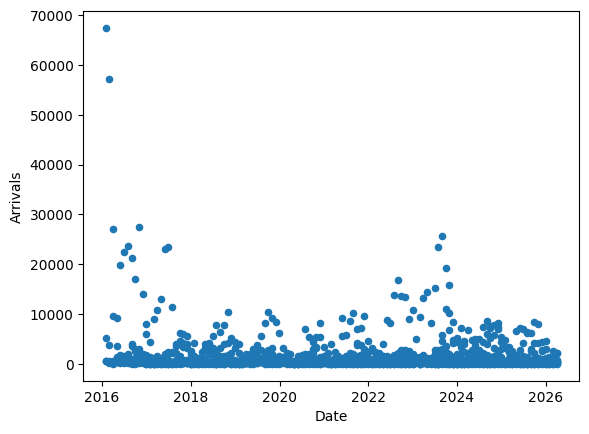

In [11]:
im1_1.plot(kind='scatter', x='Date', y='Arrivals');

In [18]:
# Here I do with second column 'Other_Countries_Areas_Monthly' from my first dataset
# 'im1' - is for first datasets, '_2' is for second column
im1_2 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'Other_Countries_Areas_Monthly')

In [19]:
im1_2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1066 entries, 0 to 1065
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1066 non-null   datetime64[ns]
 1   Year                       1066 non-null   int64         
 2   Month                      1066 non-null   int64         
 3   ISO3 - Country of arrival  1066 non-null   object        
 4   Route                      1066 non-null   object        
 5   Type of arrival            1066 non-null   object        
 6   Arrivals                   1066 non-null   int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 58.4+ KB


In [20]:
im1_2.head()

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
0,2016-01-31,2016,1,ALB,WBR,Land,55
1,2017-01-31,2017,1,ALB,WBR,Land,108
2,2018-01-31,2018,1,ALB,WBR,Land,114
3,2019-01-31,2019,1,ALB,WBR,Land,59
4,2020-01-31,2020,1,ALB,WBR,Land,156


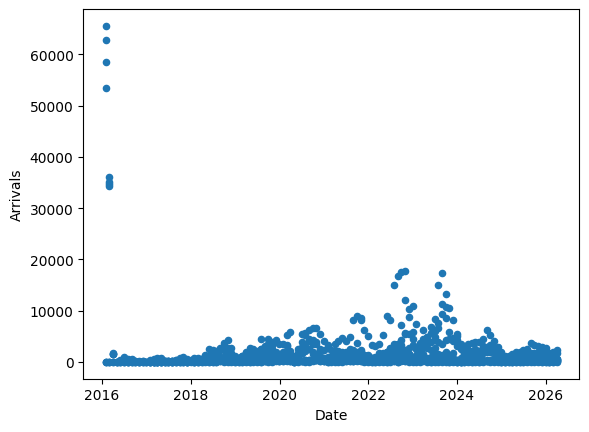

In [21]:
im1_2.plot(kind='scatter', x='Date', y='Arrivals');

In [23]:
# with the .unique() function, I checked the column 'ISO3 - Country of arrival'
# and found that among the listed countries there is Montenegro
im1_2['ISO3 - Country of arrival'].unique()

array(['ALB', 'BIH', 'HRV', 'MKD', 'MNE', 'ROU', 'SRB', 'SVN', 'XKX'],
      dtype=object)

In [29]:
# through this syntax, I extracted data related to the trend
# of illegal migration via the Balkan route from 2020 to 2025

im1_2[im1_2['Year']>2020]

,Date,Year,Month,ISO3 - Country of arrival,Route,Type of arrival,Arrivals
5,2021-01-31,2021,1,ALB,WBR,Land,777
6,2022-01-31,2022,1,ALB,WBR,Land,255
7,2023-01-31,2023,1,ALB,WBR,Land,219
8,2024-01-31,2024,1,ALB,WBR,Land,56
9,2025-01-31,2025,1,ALB,WBR,Land,72
...,...,...,...,...,...,...,...
1061,2021-12-31,2021,12,XKX,WBR,Land,69
1062,2022-12-31,2022,12,XKX,WBR,Land,141
1063,2023-12-31,2023,12,XKX,WBR,Land,49
1064,2024-12-31,2024,12,XKX,WBR,Land,60


In [31]:
# Here I do with fourth (I skip third) column 'Others_Countries_CoO' from my first dataset
# 'im1' - is for first datasets, '_4' is for fourth column

im1_4 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name='Others_Countries_CoO')

In [32]:
im1_4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439 entries, 0 to 438
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       439 non-null    datetime64[ns]
 1   Year                       439 non-null    int64         
 2   Month                      439 non-null    int64         
 3   ISO3 - Country of origin   439 non-null    object        
 4   ISO3 - Country of arrival  439 non-null    object        
 5   Route                      439 non-null    object        
 6   Arrivals                   439 non-null    int64         
 7   Source                     439 non-null    object        
dtypes: datetime64[ns](1), int64(3), object(4)
memory usage: 27.6+ KB


In [33]:
im1_4.head()

,Date,Year,Month,ISO3 - Country of origin,ISO3 - Country of arrival,Route,Arrivals,Source
0,2026-01-31,2026,1,AFG,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
1,2026-01-31,2026,1,DZA,XKX,WBR,21,"Kosovo* Ministry of Internal Affairs, Border P..."
2,2026-01-31,2026,1,EGY,XKX,WBR,15,"Kosovo* Ministry of Internal Affairs, Border P..."
3,2026-01-31,2026,1,JOR,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."
4,2026-01-31,2026,1,LBN,XKX,WBR,1,"Kosovo* Ministry of Internal Affairs, Border P..."


In [62]:
# here I saw which countries the migrants who traveled the Balkan route were from

im1_4['ISO3 - Country of origin'].unique()

array(['AFG', 'DZA', 'EGY', 'JOR', 'LBN', 'MAR', 'NGA', 'PSE', 'SDN',
       'SYR', 'TUN', 'TUR', 'IRN', 'LBY', 'NPL', 'OOO', 'RUS', 'BGD',
       'CHN', 'IND', 'PAK', 'IRQ', 'BLR', 'ERI', 'KAZ', 'UGA', 'UKR',
       'YEM', 'SOM', 'GHA', 'GIN', 'KWT', 'MLI', 'SLE', 'SSD', 'AZE',
       'CIV', 'CMR', 'GEO', 'VNM', 'BRA', 'COG', 'KEN', 'LKA', 'MMR',
       'KGZ', 'GMB', 'MEX', 'MNG', 'NER', 'SEN', 'BDI', 'COD', 'IDN',
       'TZA', 'CUB', 'ETH', 'MDA', 'PHL', 'QAT', 'SAU', 'TKM'],
      dtype=object)

In [39]:
# here I saw which countries the migrants entered by taking the Balkan route

im1_4['ISO3 - Country of arrival'].unique()

array(['XKX', 'SVN', 'ROU', 'MNE', 'MKD', 'HRV', 'BIH', 'ALB'],
      dtype=object)

In [77]:
im1_4['ISO3 - Country of arrival'].value_counts()

,count
ISO3 - Country of arrival,
BIH,120
HRV,88
MNE,59
MKD,53
ALB,41
SVN,35
XKX,30
ROU,13


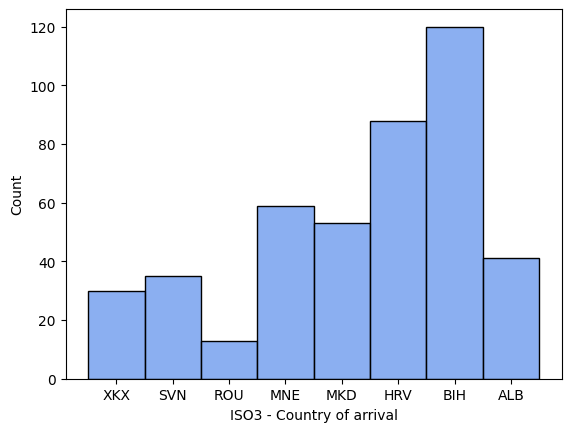

In [80]:
sns.histplot(im1_4['ISO3 - Country of arrival'], bins = 25, color = 'cornflowerblue', edgecolor = 'black');

<Axes: >

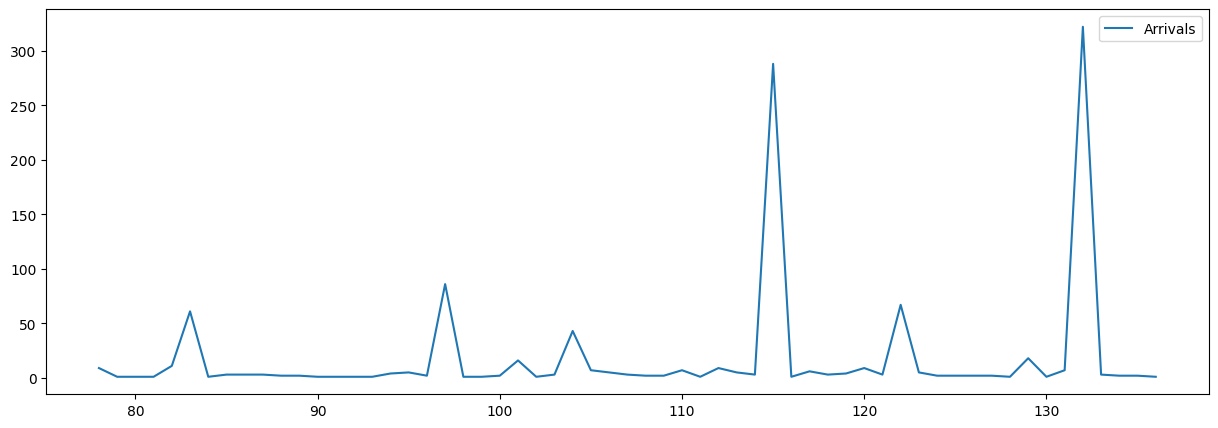

In [156]:
im1_4[(im1_4['ISO3 - Country of arrival']=='MNE')].plot(kind='line', y='Arrivals', figsize=(15,5))

In [81]:
# Here I do with fifth column 'All_Migrant_Presence' from my first dataset
# 'im1' im- is for first datasets, '_5' is for fifth column
im1_5 = pd.read_excel('/content/DTM Europe_Q1_2026_Dataset.xlsx', sheet_name= 'All_Migrant_Presence')

In [82]:
im1_5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 147 entries, 0 to 146
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 147 non-null    datetime64[ns]
 1   Year                 147 non-null    int64         
 2   Month                147 non-null    int64         
 3   Week                 147 non-null    int64         
 4   ISO3 - Host country  147 non-null    object        
 5   Individuals present  147 non-null    int64         
dtypes: datetime64[ns](1), int64(4), object(1)
memory usage: 7.0+ KB


In [96]:
im1_5.head()

,Date,Year,Month,Week,ISO3 - Host country,Individuals present
0,2026-01-04,2026,1,2,ALB,5
1,2026-01-11,2026,1,3,ALB,5
2,2026-01-18,2026,1,4,ALB,5
3,2026-01-25,2026,1,5,ALB,5
4,2026-02-01,2026,1,6,ALB,20


In [84]:
im1_5['ISO3 - Host country'].unique()

array(['ALB', 'BGR', 'BIH', 'CYP', 'GRC', 'ITA', 'MKD', 'MNE', 'ROU',
       'SRB', 'SVN', 'XKX'], dtype=object)

In [164]:
# the flow of migrants to Montenegro in 2026 is shown
im1_5[im1_5['ISO3 - Host country'] == 'MNE']

,Date,Year,Month,Week,ISO3 - Host country,Individuals present
87,2026-01-04,2026,1,2,MNE,79
88,2026-01-11,2026,1,3,MNE,60
89,2026-01-18,2026,1,4,MNE,54
90,2026-01-25,2026,1,5,MNE,44
91,2026-02-01,2026,1,6,MNE,51
92,2026-02-08,2026,2,7,MNE,68
93,2026-02-15,2026,2,8,MNE,62
94,2026-02-22,2026,2,9,MNE,73
95,2026-03-01,2026,2,10,MNE,46
96,2026-03-08,2026,3,11,MNE,46


Here I am done with the primary review of my first data set, which has a total of **2,780 rows within 5 sheets**

In [147]:
# Here I am read and searching my second exel datasets 'im2', wich have 9 but I will fokus on 5 main sheets
# below I will explore each of them in depth
im2 = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx')

In [148]:
for i, sheet in enumerate(xls2.sheet_names, start=1):
  globals()['im_%s'%str(i)] = pd.read_excel('/content/DTM Europe_Q2_2026_Dataset.xlsx', sheet_name=sheet)

In [149]:
xls2 = pd.ExcelFile('/content/DTM Europe_Q2_2026_Dataset.xlsx')
xls2.sheet_names

['About',
 'Summary',
 'First_Arrival_Countries_Monthly',
 'Other_Countries_Areas_Monthly',
 'First_Arrival_Countries_CoO',
 'Others_Countries_CoO',
 'All_Migrant_Presence',
 'Sources',
 'ISO3']

In [153]:
im2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8 non-null      object 
 1   Unnamed: 1  0 non-null      float64
 2   Unnamed: 2  0 non-null      float64
 3   Unnamed: 3  14 non-null     object 
 4   Unnamed: 4  10 non-null     object 
 5   Unnamed: 5  7 non-null      object 
 6   Unnamed: 6  7 non-null      object 
dtypes: float64(2), object(5)
memory usage: 1.6+ KB


In [151]:
im2.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Title:,NaN,NaN,DTM Flow Monitoring Europe,NaN,NaN,NaN
